# Microscopy analysis

## Setup

In [ ]:
%pip install zarr
%pip install cmap

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 405.3/405.3 kB 4.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 230.5/230.5 kB 6.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.4/1.4 MB 12.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 995.9/995.9 kB 10.0 MB/s eta 0:00:00


In [ ]:
import zarr
import matplotlib.pyplot as plt
from cmap import Colormap
import numpy as np

url = "https://data.nucleus.engineering/microscopy/nucleus-bnext-01/201009o_EsaR_mNG_0.1_0.5_K_L_2026-10-09_19-47-50.861429.zarr"
root = zarr.open_group(url, mode="r")
print(list(root.keys()))


['K', 'L']


## Plot target wells and apply consistent data mapping

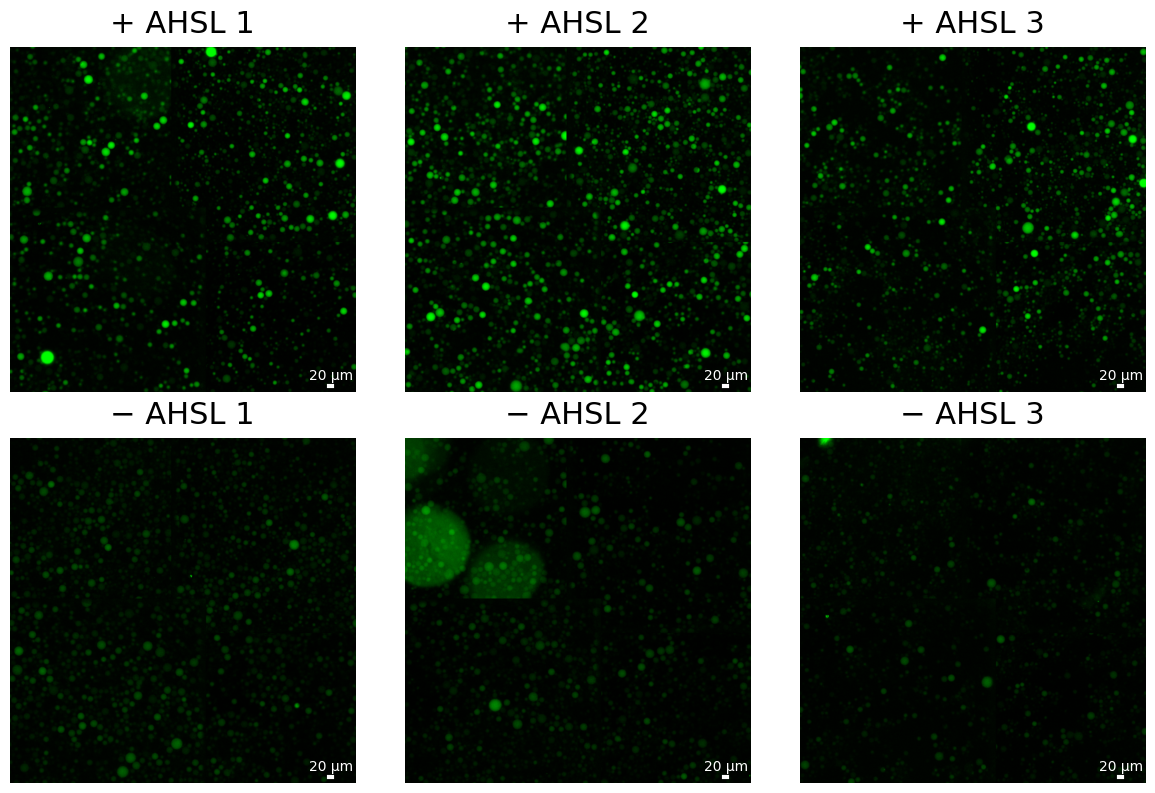

In [ ]:
#| label: microscopy-exp-01

from matplotlib.colors import LinearSegmentedColormap

gfp = LinearSegmentedColormap.from_list("gfp", ["black", "lime"])

wells = {
    ("K", "18"): "+ AHSL 1",
    ("K", "19"): "+ AHSL 2",
    ("K", "20"): "+ AHSL 3",
    ("L", "18"): "− AHSL 1",
    ("L", "19"): "− AHSL 2",
    ("L", "20"): "− AHSL 3",
}

TITLE_FONTSIZE = 22   # raise or lower to taste

fig, axes = plt.subplots(2, 3, figsize=(12, 8))
axes = axes.flatten()

y0, y1 = 4000, 7000
x0, x1 = 4000, 7000

px_um = 0.666  # µm per pixel at s1
bar_um = 20   # bar length in µm
bar_px = bar_um / px_um

for ax, ((row, col), name) in zip(axes, wells.items()):
    img = root[row][col]["0"]["s0"][-1, 0, 0, y0:y1, x0:x1]  # last timepoint, channel 0, z 0
    ax.imshow(img, cmap=gfp, vmin=1200, vmax=4500)
    ax.set_title(name, fontsize=TITLE_FONTSIZE, pad=10)
    ax.axis("off")
    x_end = (x1 - x0) - 200    # smaller number = closer to the right edge
    x_start = x_end - bar_px
    y_bar = (y1 - y0) - 50   # smaller number = closer to the bottom edge
    ax.plot([x_start, x_end], [y_bar, y_bar], color="white", lw=3)
    ax.text((x_start + x_end) / 2, y_bar - 60, f"{bar_um} µm", color="white", ha="center")

plt.tight_layout()
#plt.save_fig("MB_EsaR_GUVs_AHSL.png", dpi=600)

plt.show()

## Plotting for London Node: LuxR demo

In [ ]:
import zarr
import matplotlib.pyplot as plt
from cmap import Colormap
import numpy as np

url = "https://data.nucleus.engineering/microscopy/nucleus-bnext-01/nc_lysate_cyt_c_d_2026-10-08_20-00-25.520782.zarr"
root = zarr.open_group(url, mode="r")
print(list(root.keys()))

['C', 'D']


65535.0


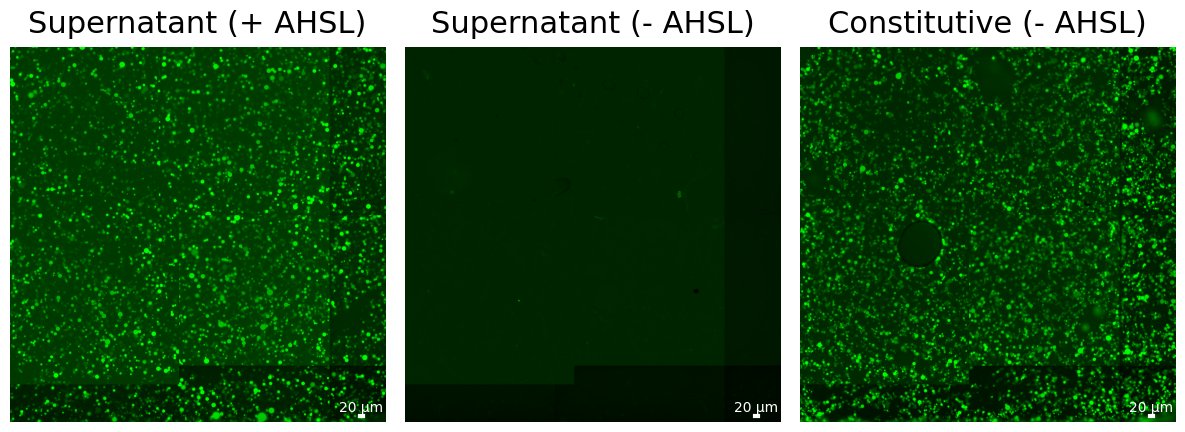

In [ ]:
import numpy as np
from matplotlib.colors import LinearSegmentedColormap

gfp = LinearSegmentedColormap.from_list("gfp", ["black", "lime"])

wells = {
    ("C", "4"): "Supernatant (+ AHSL)",
    ("C", "7"): "Supernatant (- AHSL)",
    ("C", "10"): "Constitutive (- AHSL)",
}

TITLE_FONTSIZE = 22   # raise or lower to taste

GFP = 1  # channel index: 0 = Brightfield, 1 = GFP, 2 = Alexa Fluor 647

fig, axes = plt.subplots(1, 3, figsize=(12, 8))
axes = axes.flatten()

y0, y1 = 3000, 9000
x0, x1 = 3000, 9000

px_um = 0.333  # µm per pixel at s0
bar_um = 20   # bar length in µm
bar_px = bar_um / px_um

# vmax = 99.5th percentile of a reference well, reused for every panel
ref = root["C"]["4"]["0"]["s0"][-1, GFP, 0, y0:y1, x0:x1]
vmin = 3000
vmax = np.percentile(ref, 99.5)
print(vmax)

for ax, ((row, col), name) in zip(axes, wells.items()):
    img = root[row][col]["0"]["s0"][-1, GFP, 0, y0:y1, x0:x1]  # last timepoint, GFP, z 0
    ax.imshow(img, cmap=gfp, vmin=vmin, vmax=vmax)
    ax.set_title(name, fontsize=TITLE_FONTSIZE, pad=10)
    ax.axis("off")
    x_end = (x1 - x0) - 350    # smaller number = closer to the right edge
    x_start = x_end - bar_px
    y_bar = (y1 - y0) - 100   # smaller number = closer to the bottom edge
    ax.plot([x_start, x_end], [y_bar, y_bar], color="white", lw=3)
    ax.text((x_start + x_end) / 2, y_bar - 60, f"{bar_um} µm", color="white", ha="center")

plt.tight_layout()
plt.savefig("HELP.png", dpi=600)

plt.show()

In [ ]:
meta = root["C"]["4"]["0"].attrs["ome"]
print(meta.keys())
print(meta["omero"]["channels"])

dict_keys(['omero', 'version', 'multiscales'])
[{'label': 'Brightfield', 'color': 'FFFFFF', 'active': True, 'coefficient': 1, 'family': 'linear', 'window': {'min': 0, 'max': 65535, 'start': 0, 'end': 65535}}, {'label': 'GFP', 'color': '00FF00', 'active': True, 'coefficient': 1, 'family': 'linear', 'window': {'min': 0, 'max': 65535, 'start': 0, 'end': 65535}}, {'label': 'Alexa Fluor 647', 'color': '0000FF', 'active': True, 'coefficient': 1, 'family': 'linear', 'window': {'min': 0, 'max': 65535, 'start': 0, 'end': 65535}}]
